# 01 — Magnitude of completeness (Mc)

**Question:** above which magnitude does the GOSSIP catalogue record practically every earthquake, and how has that changed since 2005?

**Why it matters:** the seismic network grew a lot after 2005. Below the magnitude of completeness, Mc, some events go undetected, so counting *all* events would partly measure the network rather than the volcano. Counting only events with M ≥ Mc gives a rate that is comparable across the years. We need this for the forecasting targets, for the Gutenberg–Richter analysis, and to reproduce the paper (arXiv 2503.20129), which used M ≥ 0.5.

**Plan for this notebook:**
1. Look at the magnitudes: their precision, their discrete values, and the cumulative magnitude distribution in different periods. *(this step)*
2. One Mc for the whole catalogue (maximum curvature, searched at Md ≥ 0.5), plus the b-value.
3. Mc over time, in moving windows.
4. Cross-check with b-value stability, with bootstrap error bars.
5. Choose the cut and compare the event count with the paper's 11,166.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.completeness import MC_SEARCH_MIN, bin_magnitudes, cumulative_counts

df = pd.read_parquet("../data/processed/catalogue.parquet")
mags = df[df["has_magnitude"]].copy()
print(f"{len(mags):,} of {len(df):,} events have a magnitude (Md); only these can be used for Mc.")

30,871 of 34,535 events have a magnitude (Md); only these can be used for Mc.


## 1a. Magnitude precision

Md is normally reported to 0.1. But from July 2021 to early September 2023 GOSSIP reports it to 0.01. The table shows the share of magnitudes with two decimals each year.

In [2]:
mags["two_decimals"] = (mags["md"] - bin_magnitudes(mags["md"])).abs() > 1e-6
by_year = mags.groupby(mags["time"].dt.year)["two_decimals"].agg(["sum", "size", "mean"])
by_year.columns = ["two_decimals", "events", "share"]
by_year.loc[2019:2024].round(2)

,two_decimals,events,share
time,,,
2019,0,701,0.00
2020,1,1323,0.00
2021,779,1965,0.40
2022,2792,2806,1.00
2023,3775,5460,0.69
2024,0,6059,0.00


Where we need a common grid (counts per bin), we round every magnitude to the nearest 0.1 with `bin_magnitudes`. The raw `md` column in the processed table stays unchanged.

*To keep in mind:* a change in reported precision may also mean a change in how Md was computed. If so, magnitudes from 2021–2023 could be shifted slightly compared with other years. Steps 3–4 (Mc and b-value over time) would show this as a jump at those dates.

## 1b. Small magnitudes take discrete values

The two-decimal period shows something the rounded years hide: below about Md 1, magnitudes take only a few fixed values. The table lists the values that occur at least 20 times in that period, and the gap to the next one.

In [3]:
two_dec_period = mags[(mags["time"] >= "2021-07-15") & (mags["time"] < "2023-09-01")]
values = two_dec_period["md"].value_counts().sort_index()
values = values[(values >= 20) & (values.index < 1.1)]
pd.DataFrame({
    "events": values,
    "gap_to_next": np.round(np.diff(values.index, append=np.nan), 2),
}).rename_axis("md")

,events,gap_to_next
md,,
-1.11,156,0.35
-0.76,763,0.27
-0.49,1217,0.22
-0.27,1256,0.19
-0.08,1014,0.17
0.09,745,0.14
0.23,536,0.13
0.36,372,0.12
0.48,263,0.10


Duration magnitude is computed from how long the shaking signal lasts, roughly Md = a + b·log₁₀(duration). The values above fit durations measured in **whole seconds**: each extra second raises Md by one step. For short, small events one second is a large relative change, so the steps are big (0.35 at the bottom); for longer events they shrink. In the other years the same values appear, rounded to one decimal (−0.8, −0.5, −0.3, −0.1, 0.1, 0.2, 0.4, …).

**Consequence:** below about Md 0.5 the steps are wider than 0.1. Some 0.1 bins then contain one value and some none, so counts per 0.1 bin jump up and down for reasons unrelated to detection, and the "most common bin" used by the maximum-curvature method is not meaningful there. Above Md 0.5 the steps are 0.1 or smaller and 0.1 bins behave normally.

So we **search for Mc only at Md ≥ 0.5** (`MC_SEARCH_MIN`). We cannot resolve an Mc below 0.5, which is acceptable: the paper used M ≥ 0.5, and the early years will need a cut at least that high.

## 1c. Cumulative magnitude distribution by period

Instead of counts per bin, we plot N(≥M): the number of events with magnitude at least M. This does not depend on how bins line up with the discrete values.

**How to read it:** for a complete catalogue, Gutenberg–Richter says log₁₀ N(≥M) = a − b·M, a straight line on a log scale. Above Mc the curve is straight; below Mc it flattens, because small events are missed. The magnitude where the curve starts to bend away from the straight line is a visual estimate of Mc. Curves for different periods differ in height (different numbers of events), so compare their shapes, not their levels.

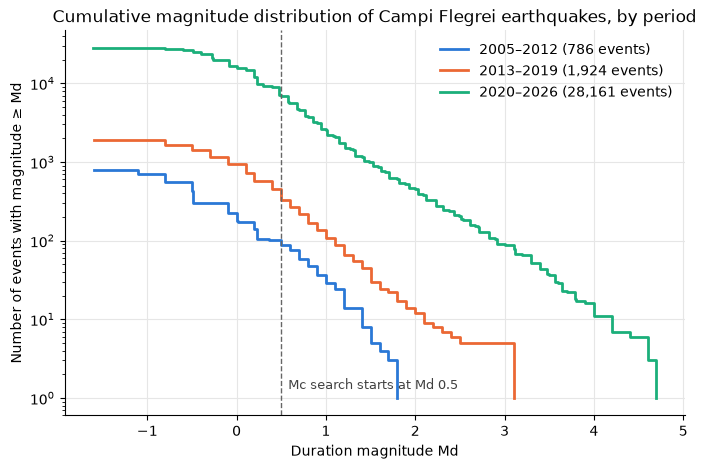

In [4]:
periods = {
    "2005–2012": ("2005-01-01", "2013-01-01"),
    "2013–2019": ("2013-01-01", "2020-01-01"),
    "2020–2026": ("2020-01-01", "2027-01-01"),
}
# Fixed colour per period (categorical palette, slots 1-3).
colours = ["#2a78d6", "#eb6834", "#1baf7a"]

fig, ax = plt.subplots(figsize=(8, 5))
for (label, (start, end)), colour in zip(periods.items(), colours):
    in_period = mags[(mags["time"] >= start) & (mags["time"] < end)]
    n = cumulative_counts(in_period["md"])
    ax.plot(n.index, n.values, drawstyle="steps-post", linewidth=2, color=colour,
            label=f"{label} ({len(in_period):,} events)")

ax.axvline(MC_SEARCH_MIN, color="0.4", linewidth=1, linestyle="--")
ax.annotate(f"Mc search starts at Md {MC_SEARCH_MIN}", (MC_SEARCH_MIN, 1.3),
            textcoords="offset points", xytext=(5, 0), fontsize=9, color="0.25")
ax.set_yscale("log")
ax.set_xlabel("Duration magnitude Md")
ax.set_ylabel("Number of events with magnitude ≥ Md")
ax.set_title("Cumulative magnitude distribution of Campi Flegrei earthquakes, by period")
ax.grid(True, which="major", color="0.9", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

**What the plot shows (by eye; steps 2–4 measure it):** for 2013–2019 and 2020–2026, the curves are close to straight lines from about Md 0.5 up to the largest events, and flatten below roughly Md 0.3. For 2005–2012 there are few events, so the curve is noisy, but it also looks roughly straight above about 0.5. So a common Mc near 0.5 looks plausible, which would match the paper's cut. The straight parts also have similar slopes, a first sign that the b-value has not changed much.